In [16]:
import pandas as pd
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis,QuadraticDiscriminantAnalysis
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

In [2]:
iris = pd.read_csv("F:\MACHINE LEARNING\SessionsMaterial\Datasets\Datasets\iris.csv")
iris.head()

,Sepal.Length,Sepal.Width,Petal.Length,Petal.Width,Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [4]:
X,y = iris.drop('Species', axis = 1), iris.Species
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.3,random_state=26,stratify=y)

In [7]:
import seaborn as sns
lda=LinearDiscriminantAnalysis().set_output(transform = 'pandas')
X_lda = lda.fit_transform(X,y)
lda_data = pd.concat([X_lda, y], axis = 1)
lda_data

,lineardiscriminantanalysis0,lineardiscriminantanalysis1,Species
0,8.061800,-0.300421,setosa
1,7.128688,0.786660,setosa
2,7.489828,0.265384,setosa
3,6.813201,0.670631,setosa
4,8.132309,-0.514463,setosa
...,...,...,...
145,-5.645003,-1.677717,virginica
146,-5.179565,0.363475,virginica
147,-4.967741,-0.821141,virginica
148,-5.886145,-2.345091,virginica


In [18]:
sd = StandardScaler()
X_train,X_test,y_train,y_test=train_test_split(X_lda,y,test_size=.3,random_state=26,stratify=y)
scores = []
for k in range(1,16):
    knn = KNeighborsClassifier(n_neighbors=k)
    pipe = Pipeline([('sc',sd),('knn',knn)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    scores.append([k, accuracy_score(y_test, pred)])
df_score = pd.DataFrame(scores, columns=['k', 'scores'])
df_score.sort_values('scores', ascending = False, ignore_index= True)

,k,scores
0,1,1.000000
1,2,0.955556
2,3,0.955556
3,4,0.955556
4,6,0.955556
5,9,0.955556
6,8,0.955556
7,12,0.955556
8,13,0.955556
9,10,0.955556


<Axes: xlabel='lineardiscriminantanalysis0', ylabel='lineardiscriminantanalysis1'>

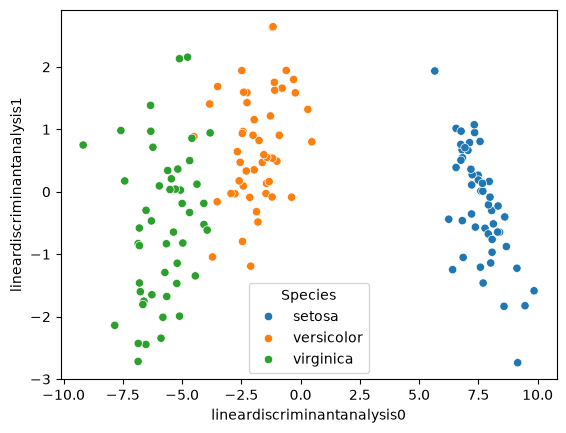

In [13]:
sns.scatterplot( data=lda_data,x = 'lineardiscriminantanalysis0',y='lineardiscriminantanalysis1',hue='Species')


In [6]:
qda=QuadraticDiscriminantAnalysis(reg_param=.9)
qda.fit(X_train,y_train)
pred2=qda.predict(X_test)
accuracy_score(y_test,pred2)

0.9333333333333333